# Day 3: SU(2)$_1$ / SU(3)$_1$ Ladders and Fibonacci Yang--Mills Dynamics

This notebook starts from a **string-network basis** in which Gauss's law has been solved, and uses the Qiskit Aer statevector simulator to study the following models.

1. $SU(2)_1$ two-leg ladder $\longleftrightarrow$ Ising qubit chain
2. Levin--Gu Hamiltonian $\longleftrightarrow$ diagonally dressed Ising paramagnet
3. $SU(3)_1$ two-leg ladder $\longleftrightarrow$ $\mathbb Z_3$ clock (qutrit) chain
4. The 18-qubit, four-plaquette periodic Fibonacci--Yang--Mills model of `quantinuum20260206.pdf` / arXiv:2601.13530

For each model, we introduce a local loop/flux excitation in the initial state and track the electric density, plaquette/Wilson observables, and survival probability. Our qubit convention is $|0\rangle=1$ (the trivial representation) and $|1\rangle=$ the nontrivial representation.

References:

- `docs/PhysRevD.111.034513.pdf`: qutrit/two-qubit representation of the $SU(3)_1$ ladder
- `docs/quantinuum20260206.pdf`, [arXiv:2601.13530](https://arxiv.org/abs/2601.13530): Fibonacci $F$-moves and the 18-qubit layout
- [Levin--Gu, arXiv:1202.3120](https://arxiv.org/abs/1202.3120): dressed-Ising representation of the $\mathbb Z_2$ SPT phase


In [4]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

simulator = AerSimulator(method="statevector")
X2 = Operator(np.array([[0, 1], [1, 0]], dtype=complex))
Z2 = Operator(np.diag([1, -1]).astype(complex))

def run_statevector(circuit):
    qc = circuit.copy()
    qc.save_statevector()
    result = simulator.run(qc).result()
    return Statevector(result.get_statevector(qc))

plt.rcParams.update({"figure.figsize": (7.2, 4.2), "font.size": 11})
print("Aer backend:", simulator.name)


Aer backend: aer_simulator_statevector


## 1. Mapping the $SU(2)_1$ Ladder to an Ising Chain

$SU(2)_1$ has only the labels $1$ and $\frac12$, with fusion rule $\frac12\times\frac12=1$. Therefore, the plaquette label $a_x\in\{0,1\}$ becomes a qubit, and the rung flux is determined by the XOR of neighboring labels.

For a bulk two-leg ladder, including the constant terms,

$$
H_E=\frac{c}{2}\sum_x(1-Z_x)+\frac{c}{4}\sum_x(1-Z_xZ_{x+1}),\qquad
H_B=-K\sum_xX_x,
$$

where $c=C_2(\frac12)=3/4$. This is a transverse-field Ising chain with a longitudinal field. We apply $X$ to the central plaquette to create a single loop excitation.


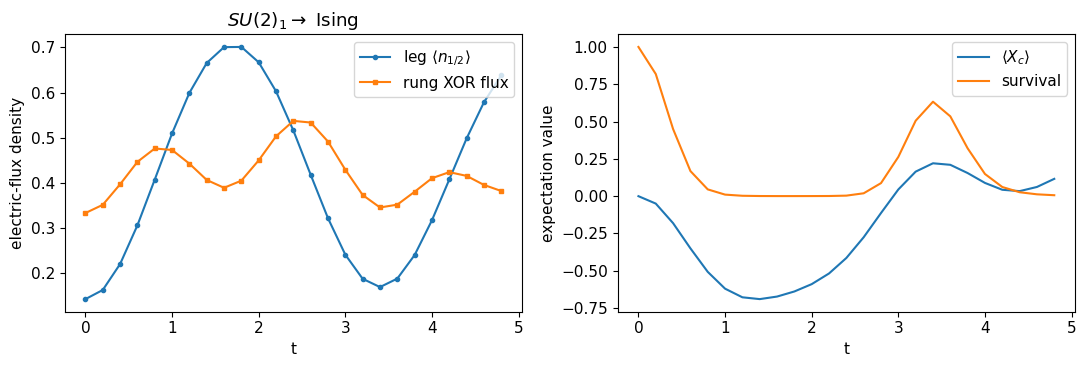

In [2]:
n_su2 = 7
c_su2 = 3 / 4
K_su2 = 0.85
dt_su2 = 0.20
n_steps_su2 = 24
center_su2 = n_su2 // 2

def su2_ising_step(n, c, K, dt):
    qc = QuantumCircuit(n)
    # exp(-i H_B dt/2)
    for q in range(n):
        qc.rx(-K * dt, q)
    # exp(-i H_E dt): leg Casimir and rung XOR flux
    for q in range(n):
        qc.p(-c * dt, q)
    for q in range(n - 1):
        qc.rzz(-c * dt / 2, q, q + 1)
    # exp(-i H_B dt/2)
    for q in range(n):
        qc.rx(-K * dt, q)
    return qc

su2_step = su2_ising_step(n_su2, c_su2, K_su2, dt_su2)
su2_initial = QuantumCircuit(n_su2)
su2_initial.x(center_su2)
psi_su2_0 = run_statevector(su2_initial)

times_su2 = dt_su2 * np.arange(n_steps_su2 + 1)
su2_leg_density = []
su2_rung_density = []
su2_wilson = []
su2_survival = []

qc = su2_initial.copy()
basis = np.arange(2**n_su2)
bits = ((basis[:, None] >> np.arange(n_su2)) & 1)
for step in range(n_steps_su2 + 1):
    state = run_statevector(qc)
    prob = np.abs(state.data) ** 2
    su2_leg_density.append(np.sum(prob[:, None] * bits) / n_su2)
    rung_xor = bits[:, :-1] ^ bits[:, 1:]
    su2_rung_density.append(np.sum(prob[:, None] * rung_xor) / (n_su2 - 1))
    su2_wilson.append(np.real(state.expectation_value(X2, [center_su2])))
    su2_survival.append(abs(np.vdot(psi_su2_0.data, state.data)) ** 2)
    if step < n_steps_su2:
        qc.compose(su2_step, inplace=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(times_su2, su2_leg_density, "o-", ms=3, label=r"leg $\langle n_{1/2}\rangle$")
ax[0].plot(times_su2, su2_rung_density, "s-", ms=3, label="rung XOR flux")
ax[0].set(xlabel="t", ylabel="electric-flux density", title=r"$SU(2)_1 \to$ Ising")
ax[0].legend()
ax[1].plot(times_su2, su2_wilson, label=r"$\langle X_{c}\rangle$")
ax[1].plot(times_su2, su2_survival, label="survival")
ax[1].set(xlabel="t", ylabel="expectation value")
ax[1].legend()
plt.tight_layout()


### Exercise 1

Set `K_su2` to $0.2$, $0.85$, and $2.0$, and compare the regime in which the initial loop remains in the electric basis for a long time with the regime in which the magnetic term spreads it. Also apply $X$ away from `center_su2` and study the interference between two loop excitations.


## 2. Computing the Levin--Gu Model as a Dressed Ising Model

On a finite triangular-lattice patch, add a domain-wall string tension to the commuting-projector terms of the Levin--Gu model and write

$$H_{\rm I}=-h\sum_iX_i+\frac{\tau}{2}\sum_{\langle ij\rangle}(1-Z_iZ_j),\qquad H_{\rm LG}=U_{\rm LG}H_{\rm I}U_{\rm LG}^\dagger.$$

$U_{\rm LG}$ is a diagonal finite-depth circuit built from $Z$, $CZ$, and $CCZ$ gates, and it commutes with the string-tension term. Consequently,

$$e^{-itH_{\rm LG}}=U_{\rm LG}e^{-itH_{\rm I}}U_{\rm LG}^\dagger,$$

so the Levin--Gu dynamics can be computed by mapping them to transverse-field Ising dynamics. We use a seven-site triangular patch consisting of one central site and a hexagonal ring. The string density is measured as $|E|^{-1}\sum_{\langle ij\rangle}\langle(1-Z_iZ_j)/2\rangle$. Time evolution uses a second-order Suzuki--Trotter decomposition, and the global phase from the constant part of the string-tension term is omitted.


max |P_Ising-P_LG| = 0.0


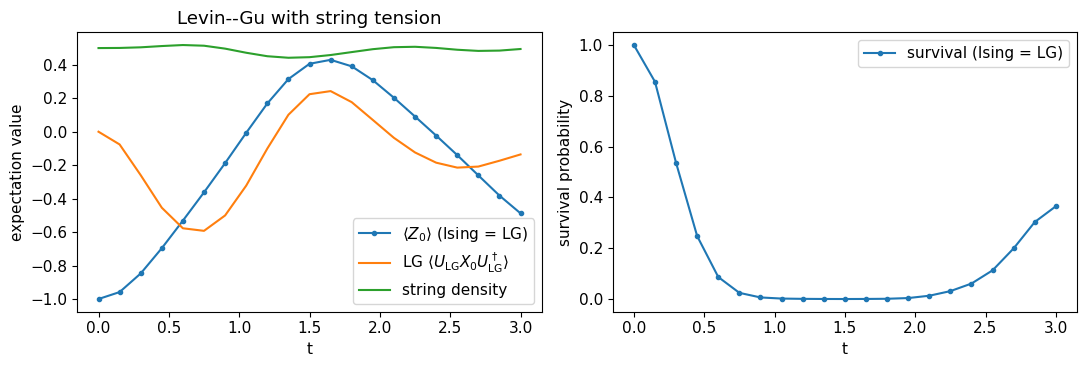

In [3]:
n_lg = 7
center_lg = 0
ring_lg = [1, 2, 3, 4, 5, 6]
edges_lg = [(0, q) for q in ring_lg] + [(ring_lg[i], ring_lg[(i + 1) % 6]) for i in range(6)]
triangles_lg = [(0, ring_lg[i], ring_lg[(i + 1) % 6]) for i in range(6)]

U_lg = QuantumCircuit(n_lg, name="U_LG")
for q in range(n_lg):
    U_lg.z(q)
for q1, q2 in edges_lg:
    U_lg.cz(q1, q2)
for q1, q2, q3 in triangles_lg:
    U_lg.ccz(q1, q2, q3)

h_lg = 1.0
tau_lg = 0.6
dt_lg = 0.15
n_steps_lg = 20
times_lg = dt_lg * np.arange(n_steps_lg + 1)

def lg_ising_step(n, edges, h, tau, dt):
    qc = QuantumCircuit(n)
    # exp(-i H_X dt/2) exp(-i H_tension dt) exp(-i H_X dt/2)
    for q in range(n):
        qc.rx(-h * dt, q)
    for q1, q2 in edges:
        qc.rzz(-tau * dt, q1, q2)
    for q in range(n):
        qc.rx(-h * dt, q)
    return qc

lg_step = lg_ising_step(n_lg, edges_lg, h_lg, tau_lg, dt_lg)
ising_initial = QuantumCircuit(n_lg)
ising_initial.x(center_lg)
psi_ising_0 = run_statevector(ising_initial)

lg_initial = ising_initial.copy()
lg_initial.compose(U_lg, inplace=True)
psi_lg_0 = run_statevector(lg_initial)

z0 = []
lg_dressed_x = []
string_density = []
ising_survival = []
lg_survival = []

basis_lg = np.arange(2**n_lg)
bits_lg = (basis_lg[:, None] >> np.arange(n_lg)) & 1
domain_wall_density = np.mean(
    np.column_stack([bits_lg[:, q1] ^ bits_lg[:, q2] for q1, q2 in edges_lg]),
    axis=1,
)

qc_i = ising_initial.copy()
for step, t in enumerate(times_lg):
    state_i = run_statevector(qc_i)

    # |psi_LG(t)> = U_LG |psi_I(t)>; move U_LG to the observable for dressed X.
    state_lg = state_i.evolve(U_lg)
    state_lg_in_ising_frame = state_lg.evolve(U_lg.inverse())

    z0.append(np.real(state_i.expectation_value(Z2, [center_lg])))
    lg_dressed_x.append(np.real(state_lg_in_ising_frame.expectation_value(X2, [center_lg])))
    string_density.append(np.dot(np.abs(state_i.data) ** 2, domain_wall_density))
    ising_survival.append(abs(np.vdot(psi_ising_0.data, state_i.data)) ** 2)
    lg_survival.append(abs(np.vdot(psi_lg_0.data, state_lg.data)) ** 2)
    if step < n_steps_lg:
        qc_i.compose(lg_step, inplace=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(times_lg, z0, "o-", ms=3, label=r"$\langle Z_0\rangle$ (Ising = LG)")
ax[0].plot(times_lg, lg_dressed_x, label=r"LG $\langle U_{\rm LG}X_0U_{\rm LG}^\dagger\rangle$")
ax[0].plot(times_lg, string_density, label="string density")
ax[0].set(xlabel="t", ylabel="expectation value", title="Levin--Gu with string tension")
ax[0].legend()
ax[1].plot(times_lg, ising_survival, "o-", ms=3, label="survival (Ising = LG)")
ax[1].set(xlabel="t", ylabel="survival probability")
ax[1].legend()
plt.tight_layout()
print("max |P_Ising-P_LG| =", np.max(np.abs(np.array(ising_survival) - np.array(lg_survival))))


In [4]:
# Fixed-point (tau_lg = 0) Levin--Gu ground-state amplitudes:
# equal magnitude with a domain-wall-dependent sign.
lg_ground = QuantumCircuit(n_lg)
lg_ground.h(range(n_lg))
lg_ground.compose(U_lg, inplace=True)
psi_lg_ground = run_statevector(lg_ground)
scaled_amplitudes = np.round(psi_lg_ground.data * np.sqrt(2**n_lg), 10)
values, counts = np.unique(scaled_amplitudes, return_counts=True)
print("sqrt(2^N) times amplitudes:", dict(zip(values, counts)))


sqrt(2^N) times amplitudes: {(-1+0j): 96, (1+0j): 32}


## 3. $SU(3)_1$ Ladder: Qutrit Clock Chain

The labels of $SU(3)_1$ are $1,3,\bar3$, and its fusion rules are those of $\mathbb Z_3$. Each plaquette therefore becomes a qutrit, and the fundamental Wilson loop is the cyclic shift

$$W|a\rangle=|a+1\pmod 3\rangle.$$

Following PRD 111, 034513, we embed the qutrit into two qubits as

$$|1\rangle\mapsto|00\rangle,\quad |3\rangle\mapsto|01\rangle,\quad |\bar3\rangle\mapsto|10\rangle.$$

The state $|11\rangle$ is unused. In the convention of PRD 111, 034513, $c=3/4$: a nontrivial label contributes $c$ to the leg electric energy, while a rung contributes $c/2$ when neighboring $\mathbb Z_3$ labels differ.


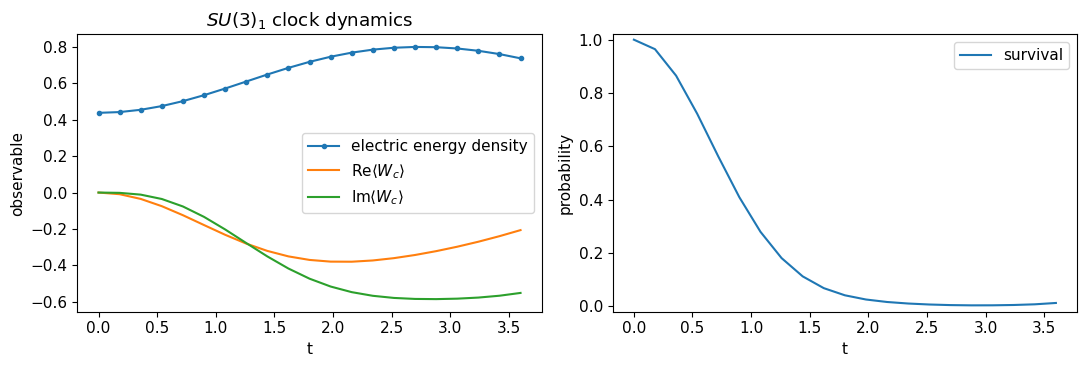

In [5]:
n_su3 = 4
nq_su3 = 2 * n_su3
c_su3 = 3 / 4
K_su3 = 0.75
dt_su3 = 0.18
n_steps_su3 = 20
center_su3 = n_su3 // 2

W3q = np.array(
    [[0, 0, 1, 0],
     [1, 0, 0, 0],
     [0, 1, 0, 0],
     [0, 0, 0, 1]], dtype=complex
)
M_leg = np.diag([0, 2, 2, 0]).astype(complex)
E_leg = Operator(c_su3 / 2 * M_leg)
U_B_half = expm(1j * K_su3 * dt_su3 / 4 * (W3q + W3q.conj().T))
U_leg = expm(-1j * dt_su3 * c_su3 / 2 * M_leg)

M_rung = np.zeros((16, 16), dtype=complex)
for index in range(16):
    left = index & 3
    right = (index >> 2) & 3
    if left < 3 and right < 3 and left != right:
        M_rung[index, index] = 1
E_rung = Operator(c_su3 / 2 * M_rung)
U_rung = expm(-1j * dt_su3 * c_su3 / 2 * M_rung)

def su3_clock_step():
    qc = QuantumCircuit(nq_su3)
    for x in range(n_su3):
        qc.append(UnitaryGate(U_B_half, label="B/2"), [2*x, 2*x + 1])
    for x in range(n_su3):
        qc.append(UnitaryGate(U_leg, label="E_leg"), [2*x, 2*x + 1])
    for x in range(n_su3 - 1):
        qc.append(UnitaryGate(U_rung, label="E_rung"), [2*x, 2*x + 1, 2*x + 2, 2*x + 3])
    for x in range(n_su3):
        qc.append(UnitaryGate(U_B_half, label="B/2"), [2*x, 2*x + 1])
    return qc

su3_step = su3_clock_step()
su3_initial = QuantumCircuit(nq_su3)
su3_initial.x(2 * center_su3)  # center qutrit: |1> -> |3>
psi_su3_0 = run_statevector(su3_initial)

times_su3 = dt_su3 * np.arange(n_steps_su3 + 1)
su3_electric = []
su3_wilson = []
su3_survival = []

qc = su3_initial.copy()
for step in range(n_steps_su3 + 1):
    state = run_statevector(qc)
    leg_energy = np.mean([
        np.real(state.expectation_value(E_leg, [2*x, 2*x + 1]))
        for x in range(n_su3)
    ])
    rung_energy = np.mean([
        np.real(state.expectation_value(
            E_rung, [2*x, 2*x + 1, 2*x + 2, 2*x + 3]
        ))
        for x in range(n_su3 - 1)
    ])
    su3_electric.append(leg_energy + rung_energy)
    su3_wilson.append(state.expectation_value(Operator(W3q), [2*center_su3, 2*center_su3 + 1]))
    su3_survival.append(abs(np.vdot(psi_su3_0.data, state.data)) ** 2)
    if step < n_steps_su3:
        qc.compose(su3_step, inplace=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(times_su3, su3_electric, "o-", ms=3, label="electric energy density")
ax[0].plot(times_su3, np.real(su3_wilson), label=r"Re$\langle W_c\rangle$")
ax[0].plot(times_su3, np.imag(su3_wilson), label=r"Im$\langle W_c\rangle$")
ax[0].set(xlabel="t", ylabel="observable", title=r"$SU(3)_1$ clock dynamics")
ax[0].legend()
ax[1].plot(times_su3, su3_survival, label="survival")
ax[1].set(xlabel="t", ylabel="probability", ylim=(-0.02, 1.02))
ax[1].legend()
plt.tight_layout()


### Exercise 2

Vary `K_su3` and compare the electric-dominated and magnetic-dominated regimes. In addition to `su3_initial.x(2*center_su3)`, flip the high bit and compare the complex phases of $\langle W\rangle$ obtained from initial $3$ and $\bar3$ excitations.


## 4. 18-Qubit Periodic Fibonacci--Yang--Mills Model

We use the decorated lattice from the Quantinuum reference without modification. Qubits 1--12 are auxiliary edges on the black triangles, while qubits 13--18 are red physical edges carrying electric tension. Magnetic terms are assigned to the four holes, and electric terms to the six red edges.

The Hamiltonian is

$$H=\frac12\sum_{e\in\mathrm{physical}}E^2(e)-K\sum_{p=1}^{4}\operatorname{tr}U_\tau(p).$$

The magnetic term is the triangular version of Eq. (7) in the paper,

$$\langle\mathbf a'|\operatorname{tr}U_\tau|\mathbf a\rangle
=\prod_{i=1}^{3}[F_{a_i'}^{c_i a_{i-1}\tau}]_{a_i a'_{i-1}},$$

and is not constructed as a dense matrix. The $F$-move is built directly from multi-controlled $X$, Toffoli, CNOT, and $R_y$ gates using the five-qubit circuit in Bonesteel--DiVincenzo, Fig. 5. When $a=d$, the reduced four-qubit $F$-move from Fig. 9 is used. Electric evolution is implemented as $F\to P(\tau)\to F^{-1}$, while magnetic evolution uses a general $F$-move, a reduced $F$-move, a tadpole phase, and the inverse $F$-moves. Observables are also evaluated directly from probabilities and amplitude correlations after the $F$-moves; no local dense matrices are constructed.

Reference: [Bonesteel and DiVincenzo, *Quantum Circuits for Measuring Levin-Wen Operators*](https://arxiv.org/abs/1206.6048)


In [5]:
phi = (1 + np.sqrt(5)) / 2
f_rotation_angle = np.arctan(phi ** -0.5)

def append_controlled_f_gate(qc, controls, target):
    # Fig. 5(b).  The paper uses R(alpha*y)=exp(+i alpha Y/2), whereas
    # Qiskit's ry(alpha)=exp(-i alpha Y/2).
    qc.ry(f_rotation_angle, target)
    qc.mcx(list(controls), target)
    qc.ry(-f_rotation_angle, target)

def append_general_f_move(qc, controls, target):
    # Bonesteel--DiVincenzo Fig. 5(a), wire order (a,b,c,d,e).
    a, b, c, d = controls
    append_controlled_f_gate(qc, controls, target)
    qc.cx(d, b)
    qc.cx(a, c)
    qc.ccx(b, c, target)
    qc.cx(a, c)
    qc.cx(d, b)

def append_special_f_move(qc, controls, target):
    # Fig. 9: identify d with a in the full F-move circuit.
    a, b, c = controls
    append_controlled_f_gate(qc, controls, target)
    qc.cx(a, b)
    qc.cx(a, c)
    qc.ccx(b, c, target)
    qc.cx(a, c)
    qc.cx(a, b)

def append_fib_electric_evolution(qc, edge, dt):
    # exp(-i dt E^2/2) = F P(-dt/2) F on (a,b,c,d,e).
    a, b, c, d, e = edge
    append_general_f_move(qc, (a, b, c, d), e)
    qc.p(-dt / 2, e)
    append_general_f_move(qc, (a, b, c, d), e)

def append_fib_plaquette_reduction(qc, face):
    a1, a2, a3, c1, c2, c3 = face
    append_general_f_move(qc, (a1, c1, c3, a2), a3)
    append_special_f_move(qc, (a1, a3, c2), a2)

def append_tadpole_evolution(qc, control, target, angle):
    # tr(U_tau) = I/2 + sqrt(5) S_P/2.  The omitted I/2 is global.
    sp_angle = np.sqrt(5) * angle / 2
    theta_bar = 2 * np.arctan(phi)
    # control=0: S_P^1 = Ry(theta_bar) Z Ry(-theta_bar).
    qc.x(control)
    qc.cry(-theta_bar, control, target)
    qc.crz(-2 * sp_angle, control, target)
    qc.cry(theta_bar, control, target)
    qc.x(control)
    # control=1: S_P^tau = Z on the logical tadpole state.
    qc.crz(-2 * sp_angle, control, target)

def append_fib_plaquette_evolution(qc, face, angle):
    # Eq. (14): general F, special F, tadpole phase, then F^{-1}.
    a1, a2, a3, c1, c2, c3 = face
    append_fib_plaquette_reduction(qc, face)
    append_tadpole_evolution(qc, a2, a1, angle)
    append_special_f_move(qc, (a1, a3, c2), a2)
    append_general_f_move(qc, (a1, c1, c3, a2), a3)

def fib_electric_expectation(state, edge):
    # Transform to the original honeycomb basis and measure P(tau) there.
    a, b, c, d, e = edge
    basis_change = QuantumCircuit(state.num_qubits)
    append_general_f_move(basis_change, (a, b, c, d), e)
    transformed = state.evolve(basis_change)
    return float(transformed.probabilities([e])[1])

def fib_wilson_regular_expectation(state, face):
    # Reduce the plaquette to a tadpole with F-moves.  In that basis
    # tr(U_reg)=(I+S_P)/2, with S_P^1=cos(theta)Z+sin(theta)X and S_P^tau=Z.
    a1, a2, _, _, _, _ = face
    reduction = QuantumCircuit(state.num_qubits)
    append_fib_plaquette_reduction(reduction, face)
    reduced = state.evolve(reduction)
    basis = np.arange(reduced.dim)
    control = (basis >> a2) & 1
    target = (basis >> a1) & 1
    probability = np.abs(reduced.data) ** 2
    z_sign = 1 - 2 * target
    z_control_0 = np.sum(probability * z_sign * (1 - control))
    z_control_1 = np.sum(probability * z_sign * control)
    x_control_0 = np.real(np.sum(np.conj(reduced.data)
                                 * reduced.data[basis ^ (1 << a1)]
                                 * (1 - control)))
    sp_expectation = (-z_control_0 + 2 * x_control_0) / np.sqrt(5) + z_control_1
    return float((1 + sp_expectation) / 2)


In [10]:
# Qubit labels below are copied from the periodic 18-qubit layout (paper labels are 1-based).
# Each magnetic tuple is (a1,a2,a3,c1,c2,c3).
magnetic_faces_1based = [
    (1, 2, 3, 15, 13, 14),
    (10, 11, 12, 18, 16, 17),
    (5, 6, 4, 15, 13, 17),
    (8, 9, 7, 18, 16, 14),
]

# Each electric tuple is (a,b,c,d,e), with e one of red physical edges 13,...,18.
electric_edges_1based = [
    (1, 2, 5, 6, 13),
    (3, 2, 9, 7, 14),
    (4, 5, 3, 1, 15),
    (10, 11, 8, 9, 16),
    (11, 12, 6, 4, 17),
    (7, 8, 12, 10, 18),
]

magnetic_faces = [tuple(q - 1 for q in face) for face in magnetic_faces_1based]
electric_edges = [tuple(q - 1 for q in edge) for edge in electric_edges_1based]

n_fib18 = 18
K_fib18 = 1.0
dt_fib18 = 0.25
trotter_steps_18 = 10  # 2 or 3 also works; runtime increases.
loop_angle = np.pi / 3

fib18_initial = QuantumCircuit(n_fib18)
append_fib_plaquette_evolution(fib18_initial, magnetic_faces[0], loop_angle)
psi_fib18_0 = run_statevector(fib18_initial)

fib18_step = QuantumCircuit(n_fib18, name="2nd-order step")
for face in magnetic_faces:
    append_fib_plaquette_evolution(fib18_step, face, K_fib18 * dt_fib18 / 2)
for edge in electric_edges:
    append_fib_electric_evolution(fib18_step, edge, dt_fib18)
for face in reversed(magnetic_faces):
    append_fib_plaquette_evolution(fib18_step, face, K_fib18 * dt_fib18 / 2)

qc_fib18 = fib18_initial.copy()
fib18_states = [psi_fib18_0]
for _ in range(trotter_steps_18):
    qc_fib18.compose(fib18_step, inplace=True)
    fib18_states.append(fib18_states[-1].evolve(fib18_step))

psi_fib18 = fib18_states[-1]
print("18-qubit circuit depth =", qc_fib18.depth())
print("18-qubit local-gate count =", len(qc_fib18.data))
print("state norm =", np.linalg.norm(psi_fib18.data))


18-qubit circuit depth = 1609
18-qubit local-gate count = 4098
state norm = 0.9999999999992037


times = [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.   2.25 2.5 ]
<H_E>(t)/N_e = [0.169672 0.231876 0.306736 0.352919 0.362334 0.355011 0.345451 0.325668
 0.284064 0.230423 0.194851]
mean regular Wilson loop(t) = [0.276393 0.319566 0.371275 0.402611 0.408282 0.4029   0.396752 0.383783
 0.355402 0.318325 0.293652]
final physical-edge tau probabilities = [0.018299 0.014954 0.018299 0.017902 0.021318 0.017902]
final electric expectations = [0.446486 0.398115 0.446486 0.314997 0.417134 0.314997]
final regular Wilson loops = [0.466749 0.332198 0.118395 0.257264]
survival probability = 0.16560882110499411


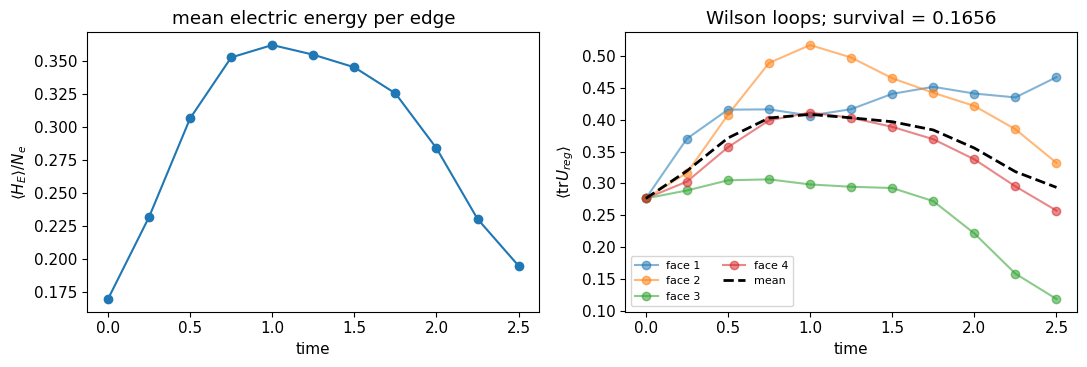

In [11]:
fib18_times = dt_fib18 * np.arange(trotter_steps_18 + 1)
fib18_electric_per_edge_history = np.array([[
    fib_electric_expectation(state, edge) for edge in electric_edges
] for state in fib18_states])
fib18_wilson_per_face_history = np.array([[
    fib_wilson_regular_expectation(state, face) for face in magnetic_faces
] for state in fib18_states])
fib18_electric_history = 0.5 * np.mean(fib18_electric_per_edge_history, axis=1)
fib18_wilson_history = np.mean(fib18_wilson_per_face_history, axis=1)

prob18 = np.abs(psi_fib18.data) ** 2
basis18 = np.arange(2**n_fib18)
physical_tau = np.array([
    np.sum(prob18 * ((basis18 >> q) & 1)) for q in range(12, 18)
])
electric_expectation = fib18_electric_per_edge_history[-1]
wilson_regular = fib18_wilson_per_face_history[-1]
fib18_survival = abs(np.vdot(psi_fib18_0.data, psi_fib18.data)) ** 2

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(fib18_times, fib18_electric_history, "o-")
ax[0].set(xlabel="time", ylabel=r"$\langle H_E\rangle/N_e$",
          title="mean electric energy per edge")
for face_index in range(4):
    ax[1].plot(fib18_times, fib18_wilson_per_face_history[:, face_index],
               "o-", alpha=0.55, label=f"face {face_index + 1}")
ax[1].plot(fib18_times, fib18_wilson_history, "k--", linewidth=2, label="mean")
ax[1].set(xlabel="time", ylabel=r"$\langle\mathrm{tr}U_{reg}\rangle$",
          title=f"Wilson loops; survival = {fib18_survival:.4f}")
ax[1].legend(ncol=2, fontsize=8)
plt.tight_layout()

print("times =", fib18_times)
print("<H_E>(t)/N_e =", np.round(fib18_electric_history, 6))
print("mean regular Wilson loop(t) =", np.round(fib18_wilson_history, 6))
print("final physical-edge tau probabilities =", np.round(physical_tau, 6))
print("final electric expectations =", np.round(electric_expectation, 6))
print("final regular Wilson loops =", np.round(wilson_regular, 6))
print("survival probability =", fib18_survival)


### Exercise 3

1. Set `trotter_steps_18 = 1, 2, 3` and compare how the Wilson-loop signal propagates from the initially excited plaquette 1 to the other plaquettes.
2. Decreasing `K_fib18` makes the electric tension dominant. Determine whether `physical_tau` or `wilson_regular` retains its initial value longer.
3. Reduce `loop_angle` to study the linear-response regime, and compare the Fibonacci model with the $SU(2)_1$ Ising model.

### Summary

- Because $SU(2)_1$ has $\mathbb Z_2$ fusion rules, it maps to an Ising qubit chain.
- Levin--Gu can be treated as an Ising model dressed by $U_{\rm LG}$, giving the same spectrum and dynamics.
- $SU(3)_1$ becomes a $\mathbb Z_3$ clock qutrit chain; in a two-qubit encoding, leakage can be monitored explicitly.
- The Fibonacci rule $\tau\times\tau=1+\tau$ produces multiple fusion channels, making $F$-moves essential.
- In the 18-qubit model, auxiliary and physical edges are separated, and the local $F$-symbol operators from the paper are implemented directly in Aer.
